# Week 07: Central limit theorem, confidence interval

**Course:** MATH7810 Python for Data Science (AY2026/27)

Open `W07_Ch4_SamplingShape_Demo.ipynb` first. The instructor runs that demonstration. This notebook is the practice that follows.

Three tasks, in order. Each uses an Input / Process / Output prompt. In Task 1 you write **Input**, **Process**, and **Output**. In Task 2 and Task 3, Input is filled in and you write Process and Output.


## Task 1 — central limit theorem

**Question:** Waiting time in the bank example is exponential with mean 10 minutes. One waiting time is right-skewed, not normal. If we take many samples, when does the histogram of the **sample means** look approximately normal?

Draw **2000** samples of size **5**, and **2000** samples of size **36** (size 36 is the sample size from the lecture example).

Write **Input**, **Process**, and **Output** yourself, then Inline Chat.

**Done when:** two histograms of sample means, each with a normal curve that has mean 10 and standard deviation $10/\sqrt{n}$. The $n = 36$ histogram sits closer to that curve than the $n = 5$ histogram.


   n   mean of x-bar      mu   sd of x-bar   10/sqrt(n)
   5           9.971    10.0         4.405        4.472
  36           9.999    10.0         1.651        1.667


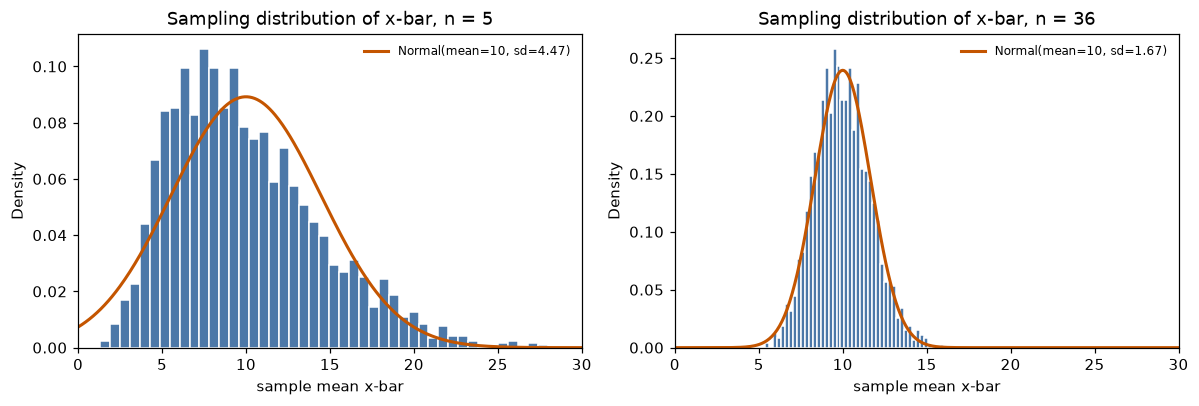

In [2]:
# Task 1 — central limit theorem
# --- Write your AI prompt here (Input → Process → Output) ---
# Input: one waiting time is Exponential with mean 10 minutes (right-skewed, not normal).
#   Draw n_rep = 2000 samples of size n = 5 and 2000 samples of size n = 36; use numpy
#   (default_rng, exponential), matplotlib.pyplot and scipy.stats.norm.
# Process: take the mean of every sample -> one x-bar per sample; the standard deviation of
#   x-bar in the sampling distribution is sigma / sqrt(n) = 10 / sqrt(n); draw a density
#   histogram of the 2000 sample means and overlay the Normal(mu = 10, sd = sigma/sqrt(n))
#   curve computed from that formula (not fitted to the bars).
# Output: one figure with two panels (n = 5 and n = 36), each a histogram of sample means
#   with the normal curve on top; the n = 36 panel sits closer to the curve.
# --- End prompt ---
# --- generated / your code below ---
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

mu = 10.0
n_rep = 2000
sample_sizes = (5, 36)

rng = np.random.default_rng(12345)
xbars = {n: rng.exponential(scale=mu, size=(n_rep, n)).mean(axis=1) for n in sample_sizes}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.linspace(0, 30, 400)

for ax, n in zip(axes, sample_sizes):
    se = mu / np.sqrt(n)
    ax.hist(xbars[n], bins=45, density=True, color="#4c78a8", edgecolor="white")
    ax.plot(x, stats.norm.pdf(x, loc=mu, scale=se), color="#c45500", lw=2,
            label=f"Normal(mean={mu:.0f}, sd={se:.2f})")
    ax.set_xlim(0, 30)
    ax.set_title(f"Sampling distribution of x-bar, n = {n}")
    ax.set_xlabel("sample mean x-bar")
    ax.set_ylabel("Density")
    ax.legend(frameon=False, fontsize=8)

fig.tight_layout()
plt.show()

print(f"{'n':>4}  {'mean of x-bar':>14}  {'mu':>6}  {'sd of x-bar':>12}  {'10/sqrt(n)':>11}")
for n in sample_sizes:
    print(f"{n:4d}  {xbars[n].mean():14.3f}  {mu:6.1f}  "
          f"{xbars[n].std(ddof=1):12.3f}  {mu / np.sqrt(n):11.3f}")

**Check:** The population of waiting times is still exponential. Which histogram of **sample means** is closer to a normal curve, and why? Type in the next cell, then **run** it.


In [4]:
# Task 1 — write BETWEEN the triple quotes, then RUN
task1_clt = """
# The n = 36 histogram is closer to the normal curve.
# The central limit theorem is about the sample mean, not about one waiting time: as n grows,
# the sampling distribution of x-bar becomes approximately normal with mean mu = 10 and
# standard deviation sigma / sqrt(n) = 10 / sqrt(n), whatever the shape of the population.
# At n = 36 that standard deviation is 10/6 = 1.67, and 2000 means already fill a bell.
# At n = 5 it is 10/sqrt(5) = 4.47 and the pile of means keeps the long right tail of the
# exponential population, so the normal curve only roughly matches the bars.
"""
print(task1_clt)


# The n = 36 histogram is closer to the normal curve.
# The central limit theorem is about the sample mean, not about one waiting time: as n grows,
# the sampling distribution of x-bar becomes approximately normal with mean mu = 10 and
# standard deviation sigma / sqrt(n) = 10 / sqrt(n), whatever the shape of the population.
# At n = 36 that standard deviation is 10/6 = 1.67, and 2000 means already fill a bell.
# At n = 5 it is 10/sqrt(5) = 4.47 and the pile of means keeps the long right tail of the
# exponential population, so the normal curve only roughly matches the bars.



## Task 2 — confidence interval for the population mean, population $\sigma$ unknown

Run the setup cell first. It loads `checkout_lab.csv`.

`purchased` is 1 or 0. `order_value` is missing when `purchased` is 0.

**Question:** Among visits **with a purchase**, what is a **95% confidence interval for the population mean** order value?

The population standard deviation of order value is not known. Use a $t$ interval.

**Done when:** the cell prints the sample size, the sample mean, and the two endpoints.


In [6]:
# Setup for Task 2 and Task 3. 
import numpy as np
from scipy import stats
import pandas as pd

# checkout_lab.csv is in the week07 folder, next to this notebook.
# One row is one visit. Task 2 and Task 3 use this table.
visits = pd.read_csv("checkout_lab.csv")

# shape is (number of rows, number of columns). head() prints the first five rows.
print("rows, columns:", visits.shape)
print(visits.head())


rows, columns: (500, 6)
  checkout_page  order_value  purchased gender browser  time_on_page
0             B        24.97          1      F  chrome         36.30
1             C        39.32          1      F  chrome         51.13
2             C        38.03          1      M  safari         48.56
3             C        25.87          1      M  chrome         24.23
4             B        20.41          1      F  safari         30.21


In [7]:
# Task 2 — confidence interval for the population mean
# --- Write your AI prompt here (Input → Process → Output) ---
# Input: the visits table from the setup cell; keep only the visits with a purchase
#   (purchased == 1, so order_value is not missing). numpy and scipy already imported.
# Process: the population sd sigma is unknown, so use the t distribution with df = n - 1:
#   xbar = mean of those order values, s = sample sd with ddof = 1, se = s / sqrt(n),
#   t* = scipy.stats.t.ppf(0.975, n - 1), margin = t* * se.
# Output: the sample size, the sample mean, and the two endpoints xbar - margin and xbar + margin.
# --- End prompt ---
# --- generated / your code below ---
import numpy as np
from scipy import stats

order = visits.loc[visits["purchased"] == 1, "order_value"]

n = int(order.size)
xbar = order.mean()
s = order.std(ddof=1)
se = s / np.sqrt(n)
t_crit = stats.t.ppf(0.975, n - 1)
margin = t_crit * se

print("sample size n        =", n)
print("sample mean x-bar    =", round(xbar, 4))
print("sample sd s          =", round(s, 4))
print("standard error       =", round(se, 4))
print("t* (df =", n - 1, ", 0.975) =", round(t_crit, 4))
print("95% CI = [", round(xbar - margin, 4), ",", round(xbar + margin, 4), "]")

sample size n        = 423
sample mean x-bar    = 30.2393
sample sd s          = 7.2046
standard error       = 0.3503
t* (df = 422 , 0.975) = 1.9656
95% CI = [ 29.5508 , 30.9279 ]


If we repeat the same sampling and calculation process 100 times, about 95 of those intervals will contain the true population mean and 5 will not.

## Task 3 — confidence interval for the population proportion

Use the same `visits` table from the setup cell.

**Question:** Among **all visits in this file**, what is a **95% confidence interval for the population proportion** who purchased?

Use a $z$ interval.

**Done when:** the cell prints the sample size, the sample proportion, and the two endpoints.


In [10]:
# Task 3 — confidence interval for the population proportion
# --- Write your AI prompt here (Input → Process → Output) ---
# Input: the same visits table; purchased is 1 or 0 for all 500 visits. numpy and scipy imported.
# Process: phat = mean of purchased; the sampling distribution of phat is approximately normal,
#   so use a z interval: se = sqrt(phat * (1 - phat) / N), z* = scipy.stats.norm.ppf(0.975),
#   margin = z* * se.
# Output: the sample size, the sample proportion, and the two endpoints phat - margin and phat + margin.
# --- End prompt ---
# --- generated / your code below ---
import numpy as np
from scipy import stats

bought = visits["purchased"]

N = int(bought.size)
phat = bought.mean()
se = np.sqrt(phat * (1 - phat) / N)
z_crit = stats.norm.ppf(0.975)
margin = z_crit * se

print("sample size N        =", N)
print("sample proportion    =", round(phat, 4))
print("standard error       =", round(se, 5))
print("z* (0.975)           =", round(z_crit, 4))
print("95% CI = [", round(phat - margin, 4), ",", round(phat + margin, 4), "]")

sample size N        = 500
sample proportion    = 0.846
standard error       = 0.01614
z* (0.975)           = 1.96
95% CI = [ 0.8144 , 0.8776 ]
